# Multivariate Distance

## 0. Setup

### 0.1 Definition

A distance is a numerical measure of how far apart two objects are, whether they are points in a geometric space, sequences, sets, probability distributions, or any other entities. It is best understood not as a length but as a formalized notion of *difference*: how much one object must change, or how much information must be discarded, to become another.

The concept underlies much of data analysis. Clustering groups objects with small mutual distances; classification and retrieval rely on nearest neighbours; anomaly detection flags points far from all others; dimensionality reduction seeks low-dimensional embeddings that preserve distances; and statistical inference uses distances between distributions to measure model fit or convergence. Its significance is that it turns qualitative resemblance into a quantity that can be computed, compared, and optimized.

Formally, a distance on a non-empty set $\mathcal{X}$ is a function

$$
d:\ \mathcal{X}\times\mathcal{X}\to\mathbb{R}
$$

that assigns to every ordered pair $(x, y)$ a real number $d(x, y)$, interpreted as the degree of separation between $x$ and $y$. Following Fréchet's abstraction of the notion in 1906, a distance is called a *metric* when, for all $x, y, z \in \mathcal{X}$, it satisfies the following axioms:

1. $d(x,y)\ge 0$ (non-negativity)
2. $d(x,y)=0\iff x=y$ (identity of indiscernibles)
3. $d(x,y)=d(y,x)$ (symmetry)
4. $d(x,z)\le d(x,y)+d(y,z)$ (triangle inequality)

The pair $(\mathcal{X}, d)$ is then a *metric space*. A distance that violates one or more of these axioms is called *non-metric*. Several special cases where a distance fails at only one axiom, but others hold, have names, although the terminology varies across the literature:

- Semi-metric: A distance lacking triangle inequality
- Pseudometric: A distance lacking identity of indiscernibles
- Quasimetric: A distance lacking symmetry

Non-metric distances are common in applications where a suitable metric does not exist or is hard to employ.

When symmetry matters but a distance is not symmetric, it can be symmetrized as

$$
d_{\text{sym}}(x, y) = \frac{d(x, y) + d(y, x)}{2}.
$$

Distance is the conceptual reverse of *similarity*: the more distant two entities are, the less similar they are, so $d(a, b) \ge d(a, c)$ corresponds to $s(a, b) \le s(a, c)$. A distance (more precisely, a dissimilarity) can therefore be derived from a similarity and vice versa. For example, let $s(x, y) \in [0, 1]$ be a similarity with $s(x, x) = 1$. Any monotonically decreasing transformation of $s$ defines a dissimilarity on the same set of objects, such as $d = 1 - s$, $d = 1/s - 1$, or $d = -\log s$. Such transformations do not guarantee that the metric axioms are preserved.

### 0.2 Notation

We have $n$ individuals measured on $p$ quantitative variables. Let

$$
\mathbf{x}_i =
\begin{bmatrix}
x_{i1}\\
x_{i2}\\
\vdots\\
x_{ip}
\end{bmatrix}
\in\mathbb{R}^p
$$

denote the observation vector for individual $i$. Then

$$
X=
\begin{bmatrix}
\mathbf x_1^\top\\
\mathbf x_2^\top\\
\vdots\\
\mathbf x_n^\top
\end{bmatrix}
\in\mathbb{R}^{n\times p}
$$

is the observation matrix. Throughout, $i$ and $j$ index individuals and $k$ indexes variables.

In [1]:
import numpy as np

X = np.array(
    [
        [170, 65, 40000],
        [180, 80, 52000],
        [175, 72, 45000],
        [165, 55, 32000],
        [185, 90, 60000],
        [180, 90, 50000],
        [180, 92, 60000]
    ],
    dtype=float
)

n, p = X.shape

## 1. Euclidean distance

A natural way to measure how different two observations (individuals) are is the straight-line distance between the corresponding points, that is, Pythagoras' theorem generalized to $p$ dimensions.

The Euclidean distance between $\mathbf{x}_i$ and $\mathbf{x}_j$ is

$$
d_E(\mathbf{x}_i, \mathbf{x}_j)
=
\sqrt{
    \sum_{k=1}^{p}
        (x_{ik} - x_{jk})^2
}
$$

or, in vector notation,

$$
d_E(\mathbf{x}_i, \mathbf{x}_j)
=
\sqrt{
    (\mathbf{x}_i - \mathbf{x}_j)^\top
    (\mathbf{x}_i - \mathbf{x}_j)
}.
$$

Equivalently, it is the norm of the difference vector,

$$
d_E(\mathbf{x}_i, \mathbf{x}_j) = \lVert \mathbf{x}_i - \mathbf{x}_j \rVert,
$$

where, for a vector $\mathbf v$,

$$
\lVert \mathbf{v} \rVert
=
\sqrt{\mathbf{v}\cdot\mathbf{v}}
=
\sqrt{\mathbf{v}^\top \mathbf{v}}
=
\sqrt{\sum_{k}v_k^2}.
$$

Define the difference vector

$$
\Delta_{ij} = \mathbf{x}_i - \mathbf{x}_j.
$$

The squared Euclidean distance then has the compact quadratic form

$$
d_E^2(i, j)
=
\Delta_{ij}^\top \Delta_{ij}
=
\sum_{k=1}^{p}
    \Delta_{ijk}^2.
$$

In [2]:
i, j = 0, 1
d_ij = X[i] - X[j]

print(np.sqrt(np.sum(d_ij ** 2)))
print(np.sqrt(np.dot(d_ij.T, d_ij)))
print(np.linalg.norm(d_ij))

12000.013541659026
12000.013541659026
12000.013541659026


## 2. Problem 1: variance (scale) of variables

Euclidean distance sums the squared differences of all variables with equal weight, so it implicitly assumes that the variables are on comparable scales. When they are not, the variables on a larger scale dominate and the effect of the others fades away. To make this visible, we can use the proportion of each variable's contribution to the squared distance.

In [3]:
d2 = d_ij ** 2
d2 / np.sum(d2)

array([6.94442877e-07, 1.56249647e-06, 9.99997743e-01])

Euclidean distance is also not scale-invariant. That is, its value depends on the units of measurement.

In [4]:
X_thousands = X.copy()
X_thousands[:, 2] /= 1000
print(np.linalg.norm(X_thousands[i] - X_thousands[j]))

21.656407827707714


### 2.1 Solution

A simple remedy is to standardize the variables first and then compute distances on the transformed data. Standardization usually means the z-score transformation, but any transformation that puts the variables on comparable scales would do.

## 3. Standardization

We use the z-score transformation, which makes the variables unitless:

$$
z_{ik}
=
\frac{x_{ik}-\bar{x}_k}{s_k},
$$

where $\bar{x}_k$ and $s_k$ are the sample mean and sample standard deviation of variable $k$. The transformed variables have mean 0 and variance 1. Indeed,

$$
n \bar{z}_k
= \sum_{i=1}^{n} z_{ik}
= \sum_{i=1}^{n}{
    \frac{x_{ik}-\bar{x}_k}{s_k}
}
= \frac{1}{s_k}
\left(
    \sum_{i=1}^{n} x_{ik} - n\bar{x}_k
\right)
= 0,
\qquad k=1, 2, \dots, p,
$$

and

$$
n s^2_{z_k}
= \sum_{i=1}^{n}
    \left( z_{ik} - \bar{z}_k \right)^2
= \sum_{i=1}^{n} z_{ik}^2
= \frac{1}{s_k^2}
\sum_{i=1}^{n}
    (x_{ik} - \bar{x}_k)^2
= n,
\qquad k=1, 2, \dots, p,
$$

since $\sum_{i=1}^{n} (x_{ik} - \bar{x}_k)^2 = ns_k^2$.

In [5]:
xbar = X.mean(axis=0)
s = X.std(axis=0)
Z = (X - xbar) / s
Z

array([[-1.00623059, -0.96251377, -0.88444739],
       [ 0.55901699,  0.17303618,  0.37476584],
       [-0.2236068 , -0.43259046, -0.35977521],
       [-1.78885438, -1.71954706, -1.72392288],
       [ 1.34164079,  0.93006948,  1.21424134],
       [ 0.55901699,  0.93006948,  0.16489697],
       [ 0.55901699,  1.08147614,  1.21424134]])

Using `ddof=1` would rescale every variable by the same constant factor $\sqrt{(n-1)/n}$. All distances would then be multiplied by that factor, so their ordering is unchanged and the variables remain on comparable scales.

In [6]:
print(Z.mean(axis=0))
print(Z.var(axis=0))

[1.90323947e-15 4.75809868e-16 9.51619735e-17]
[1. 1. 1.]


In [7]:
print(np.linalg.norm(Z[i] - Z[j]))

2.307616012628318


### 3.1 Matrix notation

Define the mean vector

$$
\boldsymbol{\mu}
=
\begin{bmatrix}
\mu_1\\
\vdots\\
\mu_p
\end{bmatrix},
$$

and the diagonal matrix of standard deviations

$$
D_\sigma
=
\operatorname{diag}(\sigma_1,\sigma_2,\ldots,\sigma_p)
=
\begin{bmatrix}
\sigma_1&0&\cdots&0\\
0&\sigma_2&\cdots&0\\
\vdots&\vdots&\ddots&\vdots\\
0&0&\cdots&\sigma_p
\end{bmatrix}.
$$

For one individual,

$$
\mathbf z_i
=
D_\sigma^{-1}
(\mathbf x_i-\boldsymbol{\mu}),
$$

and for the complete data,

$$
Z
=
(X-\mathbf 1\boldsymbol{\mu}^\top)
D_\sigma^{-1},
$$

where $\mathbf1$ is the $n$-dimensional vector of ones. To simplify the notation, define the centered observation matrix

$$
X_c=X-\mathbf 1\boldsymbol{\mu}^\top=[x_{ik}-\mu_k]_{n\times p},
$$

so that simply

$$
Z = X_c D_\sigma^{-1}.
$$

When $\mu_k$ or $\sigma_k$ are unknown, their sample estimates are substituted.

In [8]:
D_s = np.diag(s)
D_s_inv = np.linalg.inv(D_s)
D_s_inv

array([[1.56524758e-01, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 7.57033299e-02, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 1.04934436e-04]])

In [9]:
X_c = X - xbar
Z_alt = X_c @ D_s_inv
np.allclose(Z, Z_alt)

True

## 4. Standardized Euclidean distance

The standardization can be folded into the distance itself:

$$
d_{SE}(i, j)
=
\sqrt{
    \sum_{k=1}^{p}
        (z_{ik} - z_{jk})^2
}
=
\sqrt{
    \sum_{k=1}^{p}
        \left[\frac{x_{ik} - \bar{x}_k}{s_k} - \frac{x_{jk} - \bar{x}_k}{s_k}\right]^2
}
=
\sqrt{
    \sum_{k=1}^{p}
        \left(\frac{x_{ik} - x_{jk}}{s_k}\right)^2
}.
$$

In vector form,

$$
d_{SE}^2(i, j)
=
(\mathbf{z}_i - \mathbf{z}_j)^\top
(\mathbf{z}_i - \mathbf{z}_j)
=
\left[D_\sigma^{-1} \Delta_{ij}\right]^\top
\left[D_\sigma^{-1} \Delta_{ij}\right]
=
\Delta_{ij}^\top
D_\sigma^{-2}
\Delta_{ij}.
$$

In other words, standardized Euclidean distance weights each squared difference by the inverse variance of its variable.

In [10]:
print(np.sqrt(np.sum((d_ij / s) ** 2)))
print(np.sqrt(d_ij.T @ D_s_inv @ D_s_inv @ d_ij))

2.307616012628318
2.307616012628318


## 5. Problem 2: covariance of variables

Because $D_\sigma$ is diagonal, standardization rescales every variable independently and ignores the covariances between them.

Consider two strongly positively correlated variables: their observations tend to move together, so the data cloud is elongated along a diagonal direction. A displacement along that direction is expected, whereas an equally large displacement across it is unusual and therefore more informative. A good distance should give more weight to such rare directions.

### 5.1 Solution

The problem stems from ignoring the covariances between variables. We need a covariance-aware distance that reflects how "surprising" a displacement is.

## 6. Mahalanobis distance

Let

$$
\Sigma
=
\begin{bmatrix}
\sigma_1^2 & \sigma_{12} & \cdots & \sigma_{1p} \\
\sigma_{21} & \sigma_2^2 & \cdots & \sigma_{2p} \\
\vdots & \vdots & \ddots & \vdots \\
\sigma_{p1} & \sigma_{p2} & \cdots & \sigma^2_p
\end{bmatrix}
$$

denote the covariance matrix of the variables, assumed positive definite so that $\Sigma^{-1}$ exists. The Mahalanobis distance is

$$
d_M(i,j)
=
\sqrt{
\Delta_{ij}^\top
\Sigma^{-1}
\Delta_{ij}
}.
$$

In practice, $\Sigma$ is replaced by the sample covariance matrix.

In [11]:
C = np.cov(X, rowvar=False)
C_inv = np.linalg.inv(C)
print(np.sqrt(d_ij.T @ C_inv @ d_ij))

1.76087004878171


The Mahalanobis distance between individuals $i$ and $j$ (1.76) is smaller than their standardized Euclidean distance (2.3). The displacement therefore lies largely along a direction in which the data naturally vary, which makes it less surprising than a variable-by-variable comparison suggests. In general, the gap between the two distances indicates how expected a displacement is.

### 6.1 Linear transformations

Mahalanobis distance is invariant under invertible linear transformations. If

$$
\mathbf y_i = A \mathbf x_i + \mathbf b
$$

with $A$ invertible, then

$$
\Sigma_y=A\Sigma A^\top
$$

and

$$
\Delta^{y}_{ij} = \mathbf y_i - \mathbf y_j = A (\mathbf x_i - \mathbf x_j) = A \Delta_{ij}.
$$

It follows that

$$
d_M^2(\mathbf y_i, \mathbf y_j)
= \left(\Delta^{y}_{ij}\right)^\top \Sigma_y^{-1} \Delta^{y}_{ij}
= \Delta_{ij}^\top A^\top (A^\top)^{-1}\Sigma^{-1}A^{-1}A\,\Delta_{ij}
= \Delta_{ij}^\top\Sigma^{-1}\Delta_{ij}
= d_M^2(\mathbf x_i, \mathbf x_j).
$$

The z-score transformation is itself linear ($A = D_\sigma^{-1}$), so the Mahalanobis distance does not depend on the units of measurement. Standardizing merely replaces the covariance matrix by the correlation matrix, and the distance is unchanged.

In [12]:
R = np.cov(Z, rowvar=False)
R_inv = np.linalg.inv(R)
d_s_ij = Z[i] - Z[j]
print(np.sqrt(d_s_ij.T @ R_inv @ d_s_ij))

1.7608700487817088


### 6.2 Visual insights

Euclidean distance assumes a spherical space, whereas Mahalanobis distance works in an ellipsoidal one. The below figure illustrates this with a contour map with two contour lines indicating equally distant points from the center.

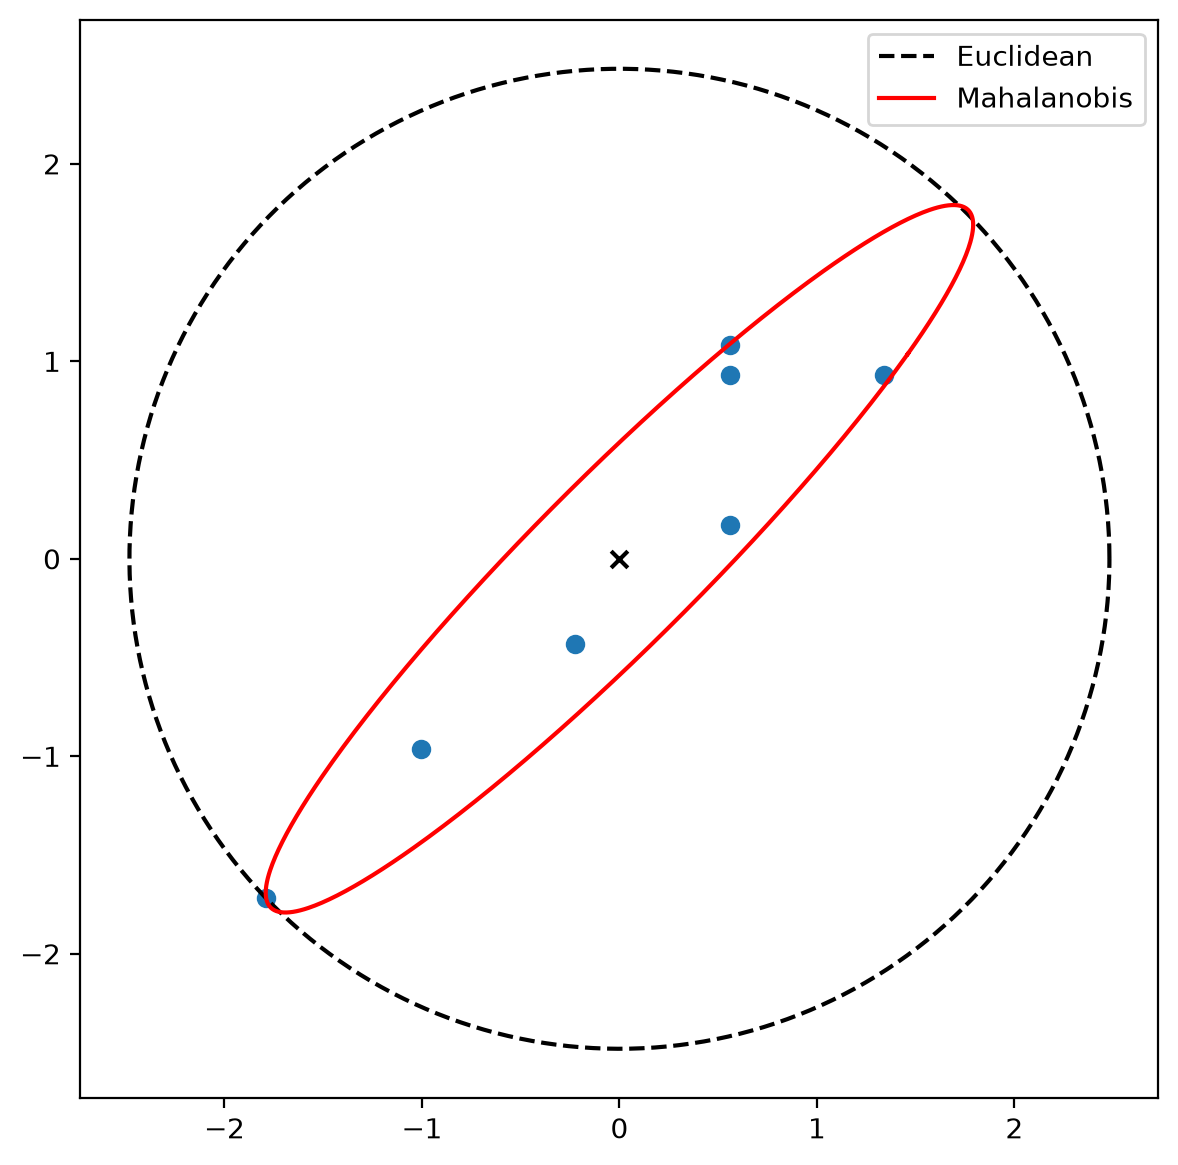

In [13]:
from matplotlib import pyplot as plt

cloud = Z[:, :2]
cov = np.cov(cloud, rowvar=False)
eigenvalues, Q = np.linalg.eigh(cov)
cov_sqrt = (Q * np.sqrt(eigenvalues)) @ Q.T
cov_inv = np.linalg.inv(cov)

idx = 3
d_E = np.linalg.norm(cloud[idx])
d_M = np.sqrt(cloud[idx].T @ cov_inv @ cloud[idx])

theta = np.linspace(0, 2 * np.pi, 500)
unit_circle = np.c_[np.cos(theta), np.sin(theta)]
circle = d_E * unit_circle
ellipsoid = d_M * unit_circle @ cov_sqrt

fig, ax = plt.subplots(figsize=(7, 7), dpi=200)
ax.scatter(*cloud.T)
ax.scatter(0, 0, color='k', marker='x')
ax.plot(*circle.T, 'k--', label='Euclidean')
ax.plot(*ellipsoid.T, "r-", label='Mahalanobis')
ax.set_aspect('equal')
ax.legend()
plt.show()

Euclidean distance says that the fourth observation has the greatest distance from the center, since no other observation is even close to the circle. On the other hand, Mahalanobis says that three observations that almost lie on the ellipsoid are equally distant from the center.

### 6.3 Special case

If the variables are uncorrelated, Mahalanobis distance reduces to standardized Euclidean distance. To see this, let

$$
\Sigma
= \operatorname{diag}(\sigma_1^2,\ldots,\sigma_p^2),
$$

then

$$
\Sigma^{-1}
=\operatorname{diag}\!\left(\frac1{\sigma_1^2},\ldots,\frac1{\sigma_p^2}\right)
= D_{\sigma}^{-2}.
$$

Now

$$
d_M^2(i, j)
= \Delta_{ij}^\top \Sigma^{-1} \Delta_{ij}
= \Delta_{ij}^\top D_{\sigma}^{-2} \Delta_{ij}
= d_{SE}^2(i, j).
$$

### 6.4 Outlier testing

For multivariate Gaussian data, the squared Mahalanobis distance to the mean follows a chi-square distribution with $p$ degrees of freedom:

$$
\mathbf x\sim\mathcal N_p(\boldsymbol\mu,\Sigma)
$$

$$
d_M^2(\mathbf x,\boldsymbol\mu)
= (\mathbf x-\boldsymbol\mu)^\top\Sigma^{-1}(\mathbf x-\boldsymbol\mu)
\;\sim\;
\chi^2_p .
$$

The idea is that an observation far from the mean is a potential outlier. To decide whether an observation is unusual, compare its p-value $P(\chi^2_p\ge d_M^2)$ with a significance level $\alpha$ (usually 0.05 or 0.01) and flag it when the p-value is smaller than $\alpha$.

When the parameters are estimated from the same sample, outliers inflate the estimates and may therefore go unrecognized. The remedy is to use robust estimates of location and scatter.

This procedure generalizes the familiar z-score rule for univariate normal data, which measures how many standard deviations an observation lies from the center. Let $x \sim \mathcal N(\mu, \sigma^2)$. An observation is considered unusual when

$$
\left|
    \frac{x - \mu}{\sigma}
\right|
= |z| > k.
$$

Rewriting the standardized magnitude shows the connection:

$$
|z|
= \sqrt{z^2}
= \sqrt{
    \left(
        \frac{x-\mu}{\sigma}
    \right)^2
}
= \sqrt{
    (x-\mu)\,\sigma^{-2}\,(x-\mu)
},
$$

which is the Mahalanobis distance for $p = 1$.

The squared Mahalanobis distance is also tied to regression leverage.

$$
d_M^2(\mathbf x_i, \boldsymbol\mu)
= (n-1)\left(h_{ii} - \frac{1}{n}\right),
$$

where $h_{ii}$ is the leverage of observation $i$, that is, the $i$-th diagonal entry of the hat matrix of $X$ after appending a column of ones. For interested readers, Cook's distance is another diagnostic for flagging influential points.

In [14]:
from scipy import stats

D2 = [
    X_c[i].T @ C_inv @ X_c[i]
    for i in range(n)
]

stats.chi2.sf(D2, p)

array([0.81498756, 0.7374523 , 0.92795697, 0.43166746, 0.46929854,
       0.16379388, 0.17642344])

In [15]:
D2 = np.einsum("ij,jk,ik->i", X_c, C_inv, X_c)
stats.chi2.sf(D2, p)

array([0.81498756, 0.7374523 , 0.92795697, 0.43166746, 0.46929854,
       0.16379388, 0.17642344])

## 7. The whitening transformation

Suppose $\Sigma$ is positive definite. Then it has a symmetric positive definite square root $\Sigma^{1/2}$, whose inverse is $\Sigma^{-1/2}$. Define the transformed observation

$$
\mathbf y_i
= \Sigma^{-1/2}
(\mathbf x_i-\boldsymbol{\mu}).
$$

For all observations at once,

$$
Y = X_c \Sigma^{-1/2},
$$

where $X_c$ is the centered observation matrix. This is the whitening transformation. The covariance matrix of the transformed variables is

$$
\operatorname{Cov}(Y)
=
\Sigma^{-1/2}\,\Sigma\,\left(\Sigma^{-1/2}\right)^\top
=
\Sigma^{-1/2}\,\Sigma\,\Sigma^{-1/2}
=
I .
$$

Whitening therefore turns the original variables into uncorrelated variables with unit variance.

### 7.1 Compute whitening

For a symmetric positive definite $\Sigma$,

$$
\Sigma=Q\Lambda Q^\top,
\qquad Q^\top Q=I,
\qquad \Lambda=\operatorname{diag}(\lambda_1,\ldots,\lambda_p),
$$

where the columns of $Q$ are the eigenvectors and $\lambda_k>0$ are the eigenvalues. Then

$$
\Sigma^{-1/2}
=
Q\Lambda^{-1/2}Q^\top,
\qquad
\Lambda^{-1/2}
=
\operatorname{diag}\!\left(\frac1{\sqrt{\lambda_1}},\ldots,\frac1{\sqrt{\lambda_p}}\right).
$$

In [16]:
def inverse_sqrt(matrix):
    eigenvalues, eigenvectors = np.linalg.eigh(matrix)
    return (eigenvectors / np.sqrt(eigenvalues)) @ eigenvectors.T


C_inv_sqrt = inverse_sqrt(C)
Y = X_c @ C_inv_sqrt

np.cov(Y, rowvar=False).round(5)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

### 7.2 Mahalanobis = Whitening + Euclidean

In the whitened space, the difference vector is

$$
\Delta_{ij}'
= \mathbf y_i - \mathbf y_j
= \Sigma^{-1/2}\,\Delta_{ij},
$$

so the squared Euclidean distance is

$$
d_E^2(\mathbf y_i,\mathbf y_j)
= \Delta_{ij}'^\top \Delta_{ij}'
= \Delta_{ij}^\top
\left(\Sigma^{-1/2}\right)^\top
\Sigma^{-1/2}\,
\Delta_{ij}
= \Delta_{ij}^\top\Sigma^{-1}\Delta_{ij}
= d_M^2(i, j),
$$

where we used

$$
\left(\Sigma^{-1/2}\right)^\top=\Sigma^{-1/2},
\qquad
\Sigma^{-1/2}\Sigma^{-1/2}=\Sigma^{-1}.
$$

So Mahalanobis distance is the Euclidean distance in whitened space.

In [17]:
print(np.linalg.norm(Y[i] - Y[j]))

1.7608700467164018


### 7.3 Principal directions

Whitening works in the basis of the principal directions: the eigenvectors of $\Sigma$ give the directions, and the eigenvalues give the variance along each.

$$
\Sigma^{-1}
=
Q\Lambda^{-1}Q^\top,
$$

$$
d_M^2(i, j)
= \Delta_{ij}^\top \Sigma^{-1} \Delta_{ij}
= \Delta_{ij}^\top Q\Lambda^{-1}Q^\top\Delta_{ij}
= \left(Q^\top\Delta_{ij}\right)^\top\Lambda^{-1}\left(Q^\top\Delta_{ij}\right)
= \sum_{k=1}^{p}
    \frac{\left(\mathbf q_k^\top \Delta_{ij}\right)^2}{\lambda_k},
$$

where $\mathbf q_k$ is the $k$-th eigenvector. Each term is the squared displacement along direction $\mathbf q_k$ divided by the variance along that direction. In this sense, Mahalanobis distance measures a displacement relative to the statistical structure of the data.

Geometrically, the data cloud is an ellipsoid whose axes are the eigenvectors, with lengths proportional to $\sqrt{\lambda_k}$. Whitening rescales each axis by $1/\sqrt{\lambda_k}$, turning the ellipsoid into a sphere.

## 8. Other distances

### 8.1 Manhattan ($L_1$)

The sum of absolute differences, as if we could only move along one axis at a time (like walking city blocks). It is the $L_1$ norm of the difference vector, and it is less dominated by a single large coordinate difference than Euclidean distance, which squares the differences:

$$
d(\mathbf x_i,\mathbf x_j) = \sum_{k=1}^{p}\lvert x_{ik} - x_{jk}\rvert .
$$

### 8.2 Minkowski ($L_q$)

A family that contains the previous distances:

$$
d(\mathbf x_i,\mathbf x_j)
=
\left(\sum_{k=1}^{p}\lvert x_{ik} - x_{jk}\rvert^{q}\right)^{1/q},
\qquad q\ge 1 .
$$

Here $q=1$ gives Manhattan distance, $q=2$ gives Euclidean distance, and $q\to\infty$ gives the Chebyshev distance $\max_k\lvert x_k-y_k\rvert$, the largest coordinate difference. For $0<q<1$ the triangle inequality fails.

### 8.3 Cosine distance

Compares the *direction* of two vectors and ignores their length:

$$
d(\mathbf x_i,\mathbf x_j)
=
1-\frac{\mathbf x_i^\top\mathbf x_j}{\lVert\mathbf x_i\rVert\,\lVert\mathbf x_j\rVert}.
$$

It is common for text and embeddings. It is not a metric (the triangle inequality can fail), although the corresponding angular distance is.

### 8.4 Correlation (Pearson) distance

$$
d(\mathbf x_i,\mathbf x_j) = 1 - r_{ij} = 1 - \operatorname{Corr}(\mathbf x_i, \mathbf x_j),
$$

where $r_{ij}$ is the Pearson correlation between the *two individuals' profiles* (computed across the $p$ variables, not across individuals). It equals the cosine distance after centering each vector by its own mean, so it ignores both level and scale and keeps only the shape of the profile. It is meaningful only when the $p$ variables are on comparable scales, and it is not a metric.

### 8.5 Jaccard distance

For binary data (0/1), treat each individual as the set of variables equal to 1:

$$
d(\mathbf x,\mathbf y)
=
1-\frac{\lvert \mathbf x\cap \mathbf y\rvert}{\lvert \mathbf x\cup \mathbf y\rvert}
=
\frac{b+c}{a+b+c},
$$

where $a$ counts the positions where both are 1, and $b$ and $c$ count the positions where only one of them is 1. Joint absences (0, 0) are ignored, which is appropriate when absence carries little information. By convention, $d=0$ when both vectors are all zeros. Unlike the two previous distances, Jaccard distance is a proper metric.

### 8.6 Notes
- Minkowski is a metric with $q\ge1$, so Euclidean and Manhattan are. Mahalanobis distance is metric too.
- The last three distances are converted similarities
- Find the appropriate distance function for a problem and not rely only on the limited number of introduced distances.

## 9. Distance matrix

For a finite set $\{\mathbf x_1,\ldots,\mathbf x_n\}$, the pairwise distances are collected in the *distance matrix* $D\in\mathbb{R}^{n\times n}$ with entries $D_{ij}=d(\mathbf x_i,\mathbf x_j)$.

A metric distance matrix has some properties implied by the axioms.

- $D_{ii}=0$
- $D_{ij} \ge 0$
- $D_{ij} = D_{ji}$
- $D_{ik} \le D_{ij} + D_{jk}$

In practice, many methods need the distance matrix of observations and not the observations matrix directly.

In [18]:
from scipy.spatial.distance import pdist, squareform

D = squareform(pdist(Y))
print(D.round(2))

[[0.   1.76 1.03 0.79 2.36 2.85 2.48]
 [1.76 0.   0.83 2.36 0.79 2.85 2.96]
 [1.03 0.83 0.   1.55 1.56 2.56 2.84]
 [0.79 2.36 1.55 0.   3.04 3.11 3.12]
 [2.36 0.79 1.56 3.04 0.   3.11 2.87]
 [2.85 2.85 2.56 3.11 3.11 0.   3.41]
 [2.48 2.96 2.84 3.12 2.87 3.41 0.  ]]


## 10. Toolkit

### 10.1 Transformations

In [19]:
def standardize(X):
    X = np.asarray(X, dtype=float)
    mean, std = X.mean(axis=0), X.std(axis=0)
    return (X - mean) / std, mean, std

In [20]:
def inverse_sqrt(matrix):
    eigenvalues, eigenvectors = np.linalg.eigh(matrix)
    return (eigenvectors / np.sqrt(eigenvalues)) @ eigenvectors.T


def whiten(X):
    X = np.asarray(X, dtype=float)
    W = inverse_sqrt(np.cov(X, rowvar=False))
    mean = X.mean(axis=0)
    return (X - mean) @ W, mean, W

### 10.2 Distances

In [21]:
def minkowski(x, y, q=2):
    return np.sum(np.abs(x - y) ** q) ** (1 / q)


def manhattan(x, y):
    return minkowski(x, y, q=1)


def euclidean(x, y):
    return minkowski(x, y, q=2)


def standardized_euclidean(x, y, std):
    return euclidean(x / std, y / std)


def mahalanobis(x, y, cov_inv):
    delta = x - y
    return np.sqrt(delta @ cov_inv @ delta)


def cosine(x, y):
    return 1 - x @ y / (np.linalg.norm(x) * np.linalg.norm(y))


def correlation(x, y):
    return cosine(x - x.mean(), y - y.mean())


def jaccard(x, y):
    x, y = x.astype(bool), y.astype(bool)
    union = np.sum(x | y)
    return 0.0 if union == 0 else 1 - np.sum(x & y) / union

### 10.3 Distance matrix

In [22]:
def distance_matrix(X, distance=euclidean, **kwargs):
    n = len(X)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            D[i, j] = distance(X[i], X[j], **kwargs)
    return D


def distance_matrix_symmetric(X, distance=euclidean, **kwargs):
    n = len(X)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            D[i, j] = D[j, i] = distance(X[i], X[j], **kwargs)
    return D

### 10.4 Validation against SciPy

In [23]:
B = np.random.default_rng(1).integers(0, 2, size=(6, 8))

checks = {
    "euclidean": (distance_matrix(X), pdist(X)),
    "manhattan": (distance_matrix(X, manhattan), pdist(X, "cityblock")),
    "standardized": (distance_matrix(X, standardized_euclidean, std=s), pdist(X, "seuclidean", V=s ** 2)),
    "mahalanobis": (distance_matrix(X, mahalanobis, cov_inv=C_inv), pdist(X, "mahalanobis", VI=C_inv)),
    "cosine": (distance_matrix(X, cosine), pdist(X, "cosine")),
    "correlation": (distance_matrix(X, correlation), pdist(X, "correlation")),
    "jaccard": (distance_matrix(B, jaccard), pdist(B, "jaccard")),
}

{
    name: np.allclose(manual, squareform(ref))
    for name, (manual, ref) in checks.items()
}

{'euclidean': True,
 'manhattan': True,
 'standardized': True,
 'mahalanobis': True,
 'cosine': True,
 'correlation': True,
 'jaccard': True}

## Closing remarks

Thank you for following this notebook to the end. I hope it gave you a clearer, more intuitive understanding of distances and the math behind them.

For more notebooks and scripts on statistical topics, visit the [Statistical-Scripts](https://github.com/sina-programer/Statistical-Scripts) repository on GitHub.